# 1R1C — heat balance and state-space matrices

```
                 Phi_HC
                   |
   T_a ---R_ia--- T_i
                   |
                  C_i
```

| symbol | unit | meaning |
|---|---|---|
| $T_i$ | °C | indoor air (state, measured) |
| $T_a$ | °C | ambient / surrounding room (disturbance) |
| $\Phi_{HC}$ | W | heating (>0) / cooling (<0) power (control); for the freezer $\Phi_{HC} = -P_{el}$ |
| $R_{ia}$ | K/W | air ↔ ambient resistance |
| $C_i$ | J/K | capacity of the air node |

With $\Phi_{HC} = -P_{el}$ (COP = 1), $R_{ia}$ and $C_i$ are effective values: the thermal values are $R_{ia}/\mathrm{COP}$ and $\mathrm{COP}\cdot C_i$.

In [1]:
import numpy as np
import sympy as sp
from IPython.display import display, Math

sp.init_printing()

def show(lhs, expr):
    display(Math(lhs + " = " + sp.latex(expr)))

## Heat balance

The heat stored in the node equals the heat flowing in through the resistance plus the supplied power:

$$C_i \frac{dT_i}{dt} = \frac{T_a - T_i}{R_{ia}} + \Phi_{HC}$$

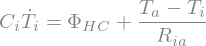

<IPython.core.display.Math object>

In [2]:
T_i, T_a, Phi_HC = sp.symbols("T_i T_a Phi_HC", real=True)
R_ia, C_i = sp.symbols("R_ia C_i", positive=True)
dT_i = sp.Symbol(r"\dot{T}_i")

balance = sp.Eq(C_i * dT_i, (T_a - T_i) / R_ia + Phi_HC)
display(balance)

sol = sp.solve(balance, dT_i, dict=True)[0]
f = sp.Matrix([sp.expand(sol[dT_i])])
show(r"\dot{T}_i", f[0])

## State-space form

The balances are linear in the states $x$, the control $u$ and the disturbances $d$, so

$$\dot x = A x + B u + E d, \qquad A = \frac{\partial f}{\partial x},\; B = \frac{\partial f}{\partial u},\; E = \frac{\partial f}{\partial d}.$$

The Jacobians are taken symbolically below, and the cell after that checks that $A x + B u + E d$ reproduces $f$ exactly.

In [3]:
x = sp.Matrix([T_i])
u = sp.Matrix([Phi_HC])
d = sp.Matrix([T_a])
A = f.jacobian(x)
B = f.jacobian(u)
E = f.jacobian(d)

show(r"x", x); show(r"u", u); show(r"d", d)
show(r"A", A)
show(r"B", B)
show(r"E", E)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [4]:
assert sp.simplify(A * x + B * u + E * d - f) == sp.zeros(*f.shape)
print("A x + B u + E d == f  ✓")

A x + B u + E d == f  ✓


## Time constant, steady state and closed-form ZOH

The single eigenvalue gives $\tau = R_{ia} C_i$. For constant inputs the steady state is $T_{i,ss} = T_a + R_{ia}\Phi_{HC}$. For one state the ZOH matrices have a closed form, $A_d = e^{-\Delta t/\tau}$ and $B_d = (1 - A_d)\,[R_{ia},\; 1]$.

In [5]:
dt = sp.Symbol(r"\Delta t", positive=True)
s = sp.Symbol("s", positive=True)

tau = -1 / A[0, 0]
show(r"\tau", sp.simplify(tau))

T_ss = sp.solve(f[0], T_i)[0]
show(r"T_{i,ss}", T_ss)

A_d = sp.exp(A[0, 0] * dt)
B_d = sp.simplify(sp.integrate(sp.exp(A[0, 0] * s), (s, 0, dt)) * B.row_join(E))
show(r"A_d", A_d)
show(r"B_d", B_d)
assert sp.simplify(B_d - (1 - A_d) * sp.Matrix([[R_ia, 1]])) == sp.zeros(1, 2)
print("B_d == (1 - A_d) [R_ia, 1]  ✓")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

B_d == (1 - A_d) [R_ia, 1]  ✓


## Discretization (as implemented in the toolbox)

With the inputs held constant over each step (zero-order hold), the exact one-step map is

$$x_k = A_d x_{k-1} + B_d \begin{bmatrix} u_k \\ d_k \end{bmatrix}, \qquad A_d = e^{A\,\Delta t}, \qquad B_d = \int_0^{\Delta t} e^{A s}\,ds\,[B \;\; E],$$

which `rctoolbox.models.discretization.zoh_discretize` evaluates with the augmented-matrix exponential

$$\exp\!\left(\begin{bmatrix} A & [B\;E] \\ 0 & 0 \end{bmatrix}\Delta t\right) = \begin{bmatrix} A_d & B_d \\ 0 & I \end{bmatrix}.$$

The input column order is therefore the stacked vector $[u; d]$ used by `calc_temperature`. The forward-Euler option steps $x_k = x_{k-1} + \Delta t\,(A x_{k-1} + B u_k + E d_k)$, which is stable only for $\Delta t < 2\tau_{\min}$.

## Check against the toolbox implementation

The symbolic matrices are evaluated for random parameter values and compared with `calc_matrices()` of the model class.

In [6]:
from rctoolbox.models.rc.one_r1c.model import OneR1C

rng = np.random.default_rng(0)
for _ in range(5):
    p = {"R_ia": rng.uniform(1e-3, 1), "C_i": rng.uniform(1e3, 1e7)}
    model = OneR1C()
    model.set_params(p)
    A_num, B_num, E_num = model.calc_matrices()

    subs = {R_ia: p["R_ia"], C_i: p["C_i"]}
    for name, S, N in [("A", A, A_num), ("B", B, B_num), ("E", E, E_num)]:
        S_num = np.array(S.subs(subs), dtype=float)
        assert np.allclose(S_num, N, rtol=1e-12, atol=0), name
print("symbolic A, B, E == OneR1C.calc_matrices()  ✓")

symbolic A, B, E == OneR1C.calc_matrices()  ✓
